[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/07-interview-prep/05_ml-system-design.ipynb)

*Interview Prep · Notebook 5 of 5*

# ML System Design

How to answer 'design a recommender, fraud or RAG system': a repeatable framework, back-of-envelope sizing, data and label problems, online vs offline metrics, serving trade-offs and monitoring.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** There's no single right design. You're being judged on how you frame the problem, weigh trade-offs and plan for failure.

**What interviewers really test here:** A clear structure, labels and leakage, sizing, offline vs online metrics, and what happens when things go wrong.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. The framework: how to answer any design question *(Basics)*
- [ ] 2. Back-of-the-envelope sizing *(Core)*
- [ ] 3. Data: where systems actually go wrong *(Core)*
- [ ] 4. From model score to business decision *(Core)*
- [ ] 5. Walkthrough: design a recommender *(Core)*
- [ ] 6. Walkthrough: design fraud detection *(Core)*
- [ ] 7. Walkthrough: design an LLM support assistant *(Core)*
- [ ] 8. Launching and keeping it healthy *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Questions you should be ready for

| Prompt | Key ideas to bring up |
| --- | --- |
| Video or product recommendations | two-stage funnel, cold start, feedback loops |
| Search ranking | query understanding, learning to rank, nDCG, position bias |
| Fraud or abuse | imbalance, delayed labels, adversaries, costs |
| Ad click prediction | calibration, huge categorical features, online learning |
| Content moderation | human review, precision and recall per severity, appeals |
| Forecasting demand | time splits, seasonality, baselines, hierarchy |
| RAG chatbot | retrieval evaluation, faithfulness, prompt injection, cost |
| Agent | tools, permissions, step limits, evals |

---
# Part 2: Lessons, step by step

## Lesson 1: The framework: how to answer any design question

*Level: Basics*

"Design a recommendation system" feels impossible because it's open-ended. There's no single right answer. The interviewer is judging how you structure the problem and weigh trade-offs. Use the same seven steps every time, and say them aloud.



| Step | Questions to ask |
| --- | --- |
| 1. Clarify | Who's it for? What scale? How fast? What's out of scope? |
| 2. Frame | What's the business metric? What's the ML task? Is ML even needed? |
| 3. Data | What's the label? What features? Is anything leaking from the future? |
| 4. Model | What's the baseline? When is a more complex one worth it? |
| 5. Evaluate | Which offline metrics? Which online experiment? |
| 6. Serve | Batch or real time? Latency and cost? What if the model fails? |
| 7. Monitor | Drift, quality, retraining, feedback loops? |



**Spend your time roughly like this** in 45 minutes: 5 clarifying, 5 framing, 10 on data, 10 on the model, 5 on evaluation, 5 on serving, and 5 on monitoring.



**Common mistakes:**



- Jumping straight to "I'd use a transformer".
- Skipping labels, even though the hardest part of a real system is often the data.
- Reporting only offline metrics, with no plan for an A/B test.
- Never mentioning a simple baseline, or what happens when the model is down.
- Going silent. Say what you're thinking, including trade-offs you rejected.

**✏️ Your turn:** you now have what you need for [Q11](#q11), [Q6](#q6). Try one now, or carry on and do them in Part 3.

## Lesson 2: Back-of-the-envelope sizing

*Level: Core*

Rough numbers guide design, so practice doing them quickly. Round freely, and **state your assumptions**.



**Traffic.** 10 million daily users × 20 requests = 200 million per day. A day has about 86,400 seconds, so about **2,300 QPS** on average. At a peak of 3×, about 6,900 QPS.



**Servers.** If one handles 100 QPS and you run at 70% utilisation, then 3,000 peak QPS needs 3000 / 70 ≈ 43, plus 2 spare = **45**.



**Memory for embeddings.** 100 million items × 768 dimensions × 4 bytes × 2 replicas = **614 GB**. That's a real constraint, and it points toward approximate indexes, compression or sharding.



**Latency budget.** For a 100 ms limit:



| Step | ms |
| --- | --- |
| Network and request handling | 5 |
| Fetch features, in parallel (10, 30, 20): the slowest counts | 30 |
| Model inference | 40 |
| Response | 5 |
| **Total** | **80 ✓** |



**A cache reduces load:** 1,000 QPS with an 80% hit rate means the model sees only 200 QPS.



**Useful numbers:** a day is about 10⁵ seconds. A memory read takes nanoseconds, a network hop within a data centre takes about a millisecond or less, and a cross-continent trip takes about 100 ms.

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q4](#q4), [Q2](#q2), [Q3](#q3), [Q5](#q5). Try one now, or carry on and do them in Part 3.

## Lesson 3: Data: where systems actually go wrong

*Level: Core*

**Labels.** Ask how you know the right answer. Clicks are plentiful but noisy, and purchases are rarer but stronger. Fraud labels may arrive 60 days later, as chargebacks, so very recent data looks falsely clean.



**Leakage** means using information that won't exist at prediction time. A warning sign is a model that's suspiciously excellent:



- `refund_issued` predicting fraud: it happens because of the fraud, after the fact.
- Random splits for time-based data: tomorrow's rows train the model that "predicts" yesterday's.
- Target encoding computed on all rows, including the current label.



The defence is **split by time**, and to compute each feature **as of** the prediction moment. For categories a, a, b, a with labels 1, 0, 1, 1 and prior 0.5, safe target encoding gives 0.5, 1.0, 0.5, 0.5. Each row sees only earlier rows.



**Training-serving skew.** A feature computed one way in a nightly batch job and differently in the live service. It's silent, since nothing crashes, and accuracy just falls. Compare the same rows from both paths. A **feature store** helps by defining each feature once.



**Imbalance.** With 0.1% fraud, you might keep all positives and just 10% of negatives. Training becomes faster, but probabilities are now inflated, so correct them: p / (p + (1 − p)/w). A prediction of 0.5 with w = 0.1 is really **0.091**. Without this, any downstream decision based on the probability will be wrong.



**High-cardinality categories,** such as millions of user IDs: use embeddings, or feature hashing into a fixed number of buckets. Collisions will happen: "ab", "ba" and "c" all land in one bucket with our simple hash. Fixed memory is what you get in exchange.

**✏️ Your turn:** you now have what you need for [Q15](#q15), [Q20](#q20), [Q12](#q12), [Q7](#q7). Try one now, or carry on and do them in Part 3.

## Lesson 4: From model score to business decision

*Level: Core*

A score isn't a decision. Connect it to money.



**Choose a threshold by cost.** If a false positive costs 1 (annoying a customer) and a false negative costs 10 (missed fraud), a threshold of 0.5 isn't special. Scores 0.9, 0.7, 0.4, 0.2 with labels 1, 0, 1, 0:



| Threshold | False positives | False negatives | Cost |
| --- | --- | --- | --- |
| 0.3 | 1 | 0 | **1** |
| 0.5 | 1 | 1 | 11 |
| 0.8 | 0 | 1 | 10 |



The chart shows this on a larger simulated data set.



**Calibration:** when the model says 90%, is it right 90% of the time? A model predicting 0.9 for all rows when only 25% are positive has a calibration error of **0.65**, however well it ranks. Calibration matters when the probability itself is used, as in pricing or expected value. It doesn't matter if you only sort.



**Limited capacity.** If reviewers can check only 100 cases a day, precision in the top 100 is what counts. **Lift** compares that with random: top-2 precision of 1.0 on a base rate of 0.4 gives lift 2.5.



| Offline metric | Good for |
| --- | --- |
| PR-AUC | rare positives |
| ROC-AUC | balanced ranking quality |
| Log-loss, calibration | when probabilities matter |
| nDCG, recall@k | ranking and retrieval |



Offline metrics only suggest a model is better. Business value is decided online, by an experiment.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

cheapest threshold: 0.425


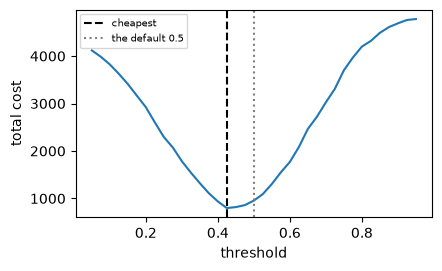

In [2]:
def cost_curve():
    rng = np.random.default_rng(0)
    y = rng.binomial(1, 0.1, 5000)
    score = np.clip(rng.normal(0.25 + 0.4 * y, 0.15), 0, 1)
    thresholds = np.linspace(0.05, 0.95, 37)
    cost = [1 * ((score >= t) & (y == 0)).sum() + 10 * ((score < t) & (y == 1)).sum() for t in thresholds]
    best = thresholds[int(np.argmin(cost))]
    print("cheapest threshold:", round(float(best), 3))
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    ax.plot(thresholds, cost)
    ax.axvline(best, color="black", linestyle="--", label="cheapest")
    ax.axvline(0.5, color="gray", linestyle=":", label="the default 0.5")
    ax.set_xlabel("threshold")
    ax.set_ylabel("total cost")
    ax.legend(fontsize=7)


cost_curve()

**✏️ Your turn:** you now have what you need for [Q14](#q14), [Q13](#q13), [Q8](#q8). Try one now, or carry on and do them in Part 3.

## Lesson 5: Walkthrough: design a recommender

*Level: Core*

**Clarify.** A video app, 10 million daily users, 10 million videos, a page within 100 ms. The goal is long-term watch time, not just clicks, since clicks reward clickbait.



**The key idea is a two-stage funnel,** because scoring 10 million items per request with a heavy model isn't possible.



| Stage | Items | Model | Goal |
| --- | --- | --- | --- |
| Candidate generation | 10M → 500 | two-tower embeddings + ANN search, plus popular and recent | high recall, fast |
| Ranking | 500 → 50 | gradient boosting or deep network, with rich features | accurate ordering |
| Re-ranking | 50 → 10 | rules | diversity, freshness, policy |



**Data.** Labels from watch time, likes and skips. Features: user history, video info, and context such as device and time. Split by time.



**Traps to raise:**



- **Cold start:** new users get popular and regional items. New videos use content embeddings and limited exploration.
- **Position bias:** top items get clicked because they're on top. An item with 2% CTR at a position seen 25% of the time really has an 8% rate, higher than a 5% item at the top.
- **Feedback loop:** you train only on what you showed. Reserve some traffic for exploration.



**Evaluate.** Offline: recall@k for retrieval, and nDCG for ranking. Online: an A/B test on watch time and retention, with guardrails such as latency and complaints.



**Serve.** Pre-compute item embeddings in batches; compute the user embedding live. If a model fails, fall back to a popular list.

**✏️ Your turn:** you now have what you need for [Q17](#q17), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 6: Walkthrough: design fraud detection

*Level: Core*

**Clarify.** Card payments: decide within 100 ms, with fraud at about 0.1%, and blocking a good customer is costly.



**Frame.** Binary classification, with three outcomes rather than two: allow, block, or send for manual review. Thresholds come from costs and from reviewer capacity.



**Data.**



- **Labels are delayed:** chargebacks can take 60 days, so the newest data isn't reliable yet.
- **Features:** velocity (cards used in the last hour), distance from the usual location, merchant history, and device signals. These must be computed as of the transaction time, typically by a streaming system.
- **Imbalance:** accuracy is useless, since always saying "not fraud" gets 99.9%. Use PR-AUC and precision at a fixed review capacity.



**Model.** Start with rules plus logistic regression as a baseline. Gradient boosting usually does well on tabular features. Keep rules for immediate response to a new attack.



**The special challenge is adversaries.** Fraudsters adapt, so performance decays. Monitor drift, retrain often, and analyse what's new. You also get no label on transactions you blocked, so let a small random sample through under controlled limits to keep an unbiased view.



**Serve.** Real time, with strict latency. If the model times out, fall back to rules. Log the features as they were seen, to prevent training-serving skew. Keep explanations available for reviewers and regulators.

**✏️ Your turn:** you now have what you need for [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 7: Walkthrough: design an LLM support assistant

*Level: Core*

**Clarify.** It answers customer questions from 50,000 help articles, and hands off to a person when unsure. Goals: resolve more tickets without wrong answers.



**Architecture:**



| Stage | Choice | Why |
| --- | --- | --- |
| Ingest | chunk by section, with titles | keep chunks self-contained |
| Retrieve | hybrid BM25 + vectors, filtered by product and permissions | catches both error codes and paraphrases |
| Re-rank | keep the top 5 | accuracy, and fewer tokens |
| Generate | answer only from sources, with citations | reduces invented answers, and lets you check |
| Act | tools such as order lookup, with checks in code | live data; risky actions need approval |
| Escalate | low retrieval score or user request → a person | the safe failure |



**Budget.** With an 8,000-token window, 500 for the system prompt, 100 for the question and 1,000 for the answer, there's room for (8000 − 1600) / 400 = **16** chunks of 400 tokens. In practice use fewer, as it's cheaper and often no worse.



**Evaluate, in layers.** Retrieval recall on questions with known articles. Answer faithfulness to sources, judged by people or an LLM rubric. Then in production, resolution rate, escalations and customer satisfaction.



**Risks to raise:** prompt injection through retrieved text or user messages; leaking data between customers, so filter at retrieval; stale documents; cost and latency, which caching helps; and model upgrades, which need your eval suite to pass first.



**Common follow-up: fine-tune or RAG?** Facts change, so use RAG. Fine-tuning suits style or format, and it's rarely the first step.

**✏️ Your turn:** you now have what you need for [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 8: Launching and keeping it healthy

*Level: Advanced*

**Roll out in stages:**



| Stage | What happens | Risk |
| --- | --- | --- |
| Shadow | new model runs and logs, but users see the old one | none for users |
| Canary | a small share of traffic | small |
| A/B test | a controlled comparison | measured |
| Full rollout | everyone, keeping an easy rollback | reversible |



**Automate the canary decision.** CTR rose 4%, which is good. But p95 latency went from 100 to 130 ms, 30% worse against a 10% limit. So **roll back**, however good the model looks.



**Batch or real time?**



|   | Batch | Real time |
| --- | --- | --- |
| Freshness | hours old | immediate |
| Cost | often lower at high volume | pay per request; needs spare capacity |
| Failure | serve yesterday's results | needs a fallback |
| Fits | daily recommendations, churn lists | fraud, search, chat |



Example: 4 runs at 50 costs 200 a day; a million calls at 0.001 costs 1,000. Batch wins, unless the use case needs fresh results.



**Monitor at three levels:** system (latency, errors), data (missing values, drift), and model (quality, often delayed by slow labels).



**Retrain on evidence,** not out of habit: a drift score above a limit, quality falling more than 5% below baseline, or a model older than your limit. Then validate the new model against the old one before promoting it.

**✏️ Your turn:** you now have what you need for [Q16](#q16), [Q9](#q9). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

<a id="q1"></a>
### Q1. Requests per Second

🟢 Warm-up · *Back of the envelope*

From daily active users and requests per user per day, return (average QPS, peak QPS at the given peak multiple), rounded to 1 decimal.

**Examples**

- `dau = 10000000, per_user = 20, peak = 3` → `(2314.8, 6944.4)`

In [ ]:
def qps(dau, per_user, peak):
    """
    From daily active users and requests per user per day, return (average QPS,
    peak QPS at the given peak multiple), rounded to 1 decimal.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(qps, [
    ((10000000, 20, 3), (2314.8, 6944.4)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Divide by seconds in a day, step by step.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One line.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Divide by seconds in a day, step by step.

```python
def qps(dau, per_user, peak):
    per_day = dau * per_user
    seconds = 24 * 60 * 60
    average = per_day / seconds
    return (round(average, 1), round(average * peak, 1))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One line.

```python
def qps(dau, per_user, peak):
    avg = dau * per_user / 86400
    return (round(avg, 1), round(avg * peak, 1))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Divide by seconds in a day, step by step. That costs O(1) time and O(1) space."

"I can do better: One line. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/ml-system-design/requests-per-second)

<a id="q2"></a>
### Q2. Embedding Storage

🟢 Warm-up · *Will it fit in memory?*

Return the GB (10⁹ bytes) needed for n vectors of dimension d, at 4 bytes each, times a replication factor.

**Examples**

- `n = 100000000, d = 768, replicas = 2` → `614.4`
- `n = 1000000, d = 384, replicas = 1` → `1.54`

In [ ]:
def embedding_gb(n, d, replicas):
    """
    Return the GB (10⁹ bytes) needed for n vectors of dimension d, at 4 bytes
    each, times a replication factor.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(embedding_gb, [
    ((100000000, 768, 2), 614.4),
    ((1000000, 384, 1), 1.54),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply one step at a time.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One line.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Multiply one step at a time.

```python
def embedding_gb(n, d, replicas):
    bytes_each = d * 4
    total = n * bytes_each * replicas
    return round(total / 1e9, 2)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One line.

```python
def embedding_gb(n, d, replicas):
    return round(n * d * 4 * replicas / 1e9, 2)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply one step at a time. That costs O(1) time and O(1) space."

"I can do better: One line. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/ml-system-design/embedding-storage)

<a id="q3"></a>
### Q3. Latency Budget

🟢 Warm-up · *Where the time goes*

Steps run in sequence, except that fetches in one list run in parallel. Given steps as numbers or lists, return the total ms and whether it meets the budget.

**Examples**

- `steps = [5, [10, 30, 20], 40, 5], budget = 100` → `(80, True)`
- `steps = [50, [60], 10], budget = 100` → `(120, False)`

In [ ]:
def latency_budget(steps, budget):
    """
    Steps run in sequence, except that fetches in one list run in parallel.
    Given steps as numbers or lists, return the total ms and whether it meets
    the budget.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(latency_budget, [
    (([5, [10, 30, 20], 40, 5], 100), (80, True)),
    (([50, [60], 10], 100), (120, False)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop with a type check.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A generator with `max`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop with a type check.

```python
def latency_budget(steps, budget):
    total = 0
    for s in steps:
        if isinstance(s, list):
            total += max(s)
        else:
            total += s
    return (total, total <= budget)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A generator with `max`.

```python
def latency_budget(steps, budget):
    total = sum(max(s) if isinstance(s, list) else s for s in steps)
    return (total, total <= budget)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop with a type check. That costs O(n) time and O(1) space."

"I can do better: A generator with `max`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/ml-system-design/latency-budget)

<a id="q4"></a>
### Q4. How Many Servers?

🟢 Warm-up · *Capacity*

Each server handles qps\_each at target\_util utilisation. Return the servers needed for the peak, rounded up, plus spare (N+spare).

**Examples**

- `peak = 3000, qps_each = 100, target_util = 0.7, spare = 2` → `45`

In [ ]:
def servers_needed(peak, qps_each, target_util, spare):
    """
    Each server handles qps_each at target_util utilisation. Return the servers
    needed for the peak, rounded up, plus spare (N+spare).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(servers_needed, [
    ((3000, 100, 0.7, 2), 45),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Usable capacity, then divide.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One line.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Usable capacity, then divide.

```python
def servers_needed(peak, qps_each, target_util, spare):
    usable = qps_each * target_util
    need = math.ceil(peak / usable)
    return need + spare
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One line.

```python
def servers_needed(peak, qps_each, target_util, spare):
    return math.ceil(peak / (qps_each * target_util)) + spare
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Usable capacity, then divide. That costs O(1) time and O(1) space."

"I can do better: One line. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/ml-system-design/how-many-servers)

<a id="q5"></a>
### Q5. Cache Effect on Traffic

🟢 Warm-up · *Reducing load*

Return the QPS reaching the model after a cache with the given hit rate, and the model's cost per day at cost\_per\_1k calls (a made-up rate), rounded to 2 decimals.

**Examples**

- `qps = 1000, hit_rate = 0.8, cost_per_1k = 0.5` → `(200.0, 8640.0)`

In [ ]:
def after_cache(qps, hit_rate, cost_per_1k):
    """
    Return the QPS reaching the model after a cache with the given hit rate, and
    the model's cost per day at cost_per_1k calls (a made-up rate), rounded to 2
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(after_cache, [
    ((1000, 0.8, 0.5), (200.0, 8640.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Misses, then calls per day, then cost.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One line each.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Misses, then calls per day, then cost.

```python
def after_cache(qps, hit_rate, cost_per_1k):
    misses = qps * (1 - hit_rate)
    calls = misses * 86400
    return (round(misses, 2), round(calls / 1000 * cost_per_1k, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One line each.

```python
def after_cache(qps, hit_rate, cost_per_1k):
    m = qps * (1 - hit_rate)
    return (round(m, 2), round(m * 86.4 * cost_per_1k, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Misses, then calls per day, then cost. That costs O(1) time and O(1) space."

"I can do better: One line each. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/ml-system-design/cache-effect-on-traffic)

<a id="q6"></a>
### Q6. Split by Time

🟢 Warm-up · *Prevent leakage*

Rows are (timestamp, label). Train on everything before the cut time, test on the rest. Return (train labels, test labels), keeping time order.

**Examples**

- `rows = [(3, 'c'), (1, 'a'), (4, 'd'), (2, 'b')], cut = 3` → `(['a', 'b'], ['c', 'd'])`

In [ ]:
def time_split(rows, cut):
    """
    Rows are (timestamp, label). Train on everything before the cut time, test
    on the rest. Return (train labels, test labels), keeping time order.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(time_split, [
    (([(3, 'c'), (1, 'a'), (4, 'd'), (2, 'b')], 3), (['a', 'b'], ['c', 'd'])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort, then two loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Sort, then binary search for the cut.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Sort, then two loops.

```python
def time_split(rows, cut):
    ordered = sorted(rows)
    train, test = [], []
    for t, y in ordered:
        if t < cut:
            train.append(y)
        else:
            test.append(y)
    return (train, test)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Sort, then binary search for the cut.

```python
def time_split(rows, cut):
    import bisect
    ordered = sorted(rows)
    i = bisect.bisect_left([t for t, _ in ordered], cut)
    return ([y for _, y in ordered[:i]], [y for _, y in ordered[i:]])
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort, then two loops. That costs O(n log n) time and O(n) space."

"I can do better: Sort, then binary search for the cut. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/ml-system-design/split-by-time)

<a id="q7"></a>
### Q7. Feature Hashing

🟢 Warm-up · *Huge vocabularies in fixed space*

Map each string to a bucket with (sum of character codes) mod m (a stand-in for a real hash). Return bucket counts.

**Examples**

- `items = ['ab', 'ba', 'c'], m = 4` → `[0, 0, 0, 3]`

In [ ]:
def hash_features(items, m):
    """
    Map each string to a bucket with (sum of character codes) mod m (a stand-in
    for a real hash). Return bucket counts.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(hash_features, [
    ((['ab', 'ba', 'c'], 4), [0, 0, 0, 3]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop and add.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.bincount`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Loop and add.

```python
def hash_features(items, m):
    out = [0] * m
    for s in items:
        total = 0
        for ch in s:
            total += ord(ch)
        out[total % m] += 1
    return out
```

**Cost:** O(total) time, O(m) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.bincount`.

```python
def hash_features(items, m):
    return np.bincount([sum(map(ord, s)) % m for s in items], minlength=m)
```

**Cost:** O(total) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop and add. That costs O(total) time and O(m) space."

"I can do better: `np.bincount`. That's O(total) time and O(m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/ml-system-design/feature-hashing)

<a id="q8"></a>
### Q8. Lift at the Top

🟢 Warm-up · *When you can only review some*

Return precision in the top k by score, and lift (that ÷ overall positive rate), rounded to 4 decimals.

**Examples**

- `scores = [0.9, 0.8, 0.3, 0.2, 0.1], y = [1, 1, 0, 0, 0], k = 2` → `(1.0, 2.5)`

In [ ]:
def lift_at_k(scores, y, k):
    """
    Return precision in the top k by score, and lift (that ÷ overall positive
    rate), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(lift_at_k, [
    (([0.9, 0.8, 0.3, 0.2, 0.1], [1, 1, 0, 0, 0], 2), (1.0, 2.5)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort pairs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`argsort`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Sort pairs.

```python
def lift_at_k(scores, y, k):
    pairs = sorted(zip(scores, y), reverse=True)
    hits = sum(t for _, t in pairs[:k])
    precision = hits / k
    return (round(precision, 4), round(precision / (sum(y) / len(y)), 4))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `argsort`.

```python
def lift_at_k(scores, y, k):
    s, y = np.array(scores), np.array(y)
    precision = y[np.argsort(-s)[:k]].mean()
    return (round(float(precision), 4), round(float(precision / y.mean()), 4))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort pairs. That costs O(n log n) time and O(n) space."

"I can do better: `argsort`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/ml-system-design/lift-at-the-top)

<a id="q9"></a>
### Q9. When to Retrain

🟢 Warm-up · *Triggers, not a habit*

Retrain if drift (PSI) exceeds 0.25, the live metric fell more than 5% below baseline, or the model is older than max\_age days. Return the reasons, in that order.

**Examples**

- `psi = 0.3, metric = 0.8, baseline = 0.9, age = 10, max_age = 30` → `['drift', 'quality']`
- `psi = 0.05, metric = 0.89, baseline = 0.9, age = 40, max_age = 30` → `['age']`
- `psi = 0.05, metric = 0.89, baseline = 0.9, age = 10, max_age = 30` → `[]`

In [ ]:
def retrain_reasons(psi, metric, baseline, age, max_age):
    """
    Retrain if drift (PSI) exceeds 0.25, the live metric fell more than 5% below
    baseline, or the model is older than max_age days. Return the reasons, in
    that order.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(retrain_reasons, [
    ((0.3, 0.8, 0.9, 10, 30), ['drift', 'quality']),
    ((0.05, 0.89, 0.9, 40, 30), ['age']),
    ((0.05, 0.89, 0.9, 10, 30), []),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Three ifs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A filtered list of pairs.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Three ifs.

```python
def retrain_reasons(psi, metric, baseline, age, max_age):
    out = []
    if psi > 0.25:
        out.append("drift")
    if metric < baseline * 0.95:
        out.append("quality")
    if age > max_age:
        out.append("age")
    return out
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A filtered list of pairs.

```python
def retrain_reasons(psi, metric, baseline, age, max_age):
    checks = [("drift", psi > 0.25), ("quality", metric < baseline * 0.95), ("age", age > max_age)]
    return [name for name, hit in checks if hit]
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Three ifs. That costs O(1) time and O(1) space."

"I can do better: A filtered list of pairs. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/ml-system-design/when-to-retrain)

<a id="q10"></a>
### Q10. RAG Assistant Budget

🟢 Warm-up · *An LLM system design staple*

Given a context window, system prompt tokens, question tokens, reserved answer tokens and chunk size, return how many chunks fit.

**Examples**

- `window = 8000, system = 500, question = 100, answer = 1000, chunk = 400` → `16`
- `window = 1000, system = 500, question = 100, answer = 500, chunk = 400` → `0`

In [ ]:
def chunks_that_fit(window, system, question, answer, chunk):
    """
    Given a context window, system prompt tokens, question tokens, reserved
    answer tokens and chunk size, return how many chunks fit.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(chunks_that_fit, [
    ((8000, 500, 100, 1000, 400), 16),
    ((1000, 500, 100, 500, 400), 0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Subtract one at a time, then divide.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One line, floored at 0.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Subtract one at a time, then divide.

```python
def chunks_that_fit(window, system, question, answer, chunk):
    room = window - system
    room = room - question
    room = room - answer
    if room < 0:
        return 0
    return room // chunk
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One line, floored at 0.

```python
def chunks_that_fit(window, system, question, answer, chunk):
    return max(0, window - system - question - answer) // chunk
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Subtract one at a time, then divide. That costs O(1) time and O(1) space."

"I can do better: One line, floored at 0. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/ml-system-design/rag-assistant-budget)

<a id="q11"></a>
### Q11. Spot Feature Leakage

🟡 Interview standard · *Too good to be true*

A feature is suspect if |correlation with the label| exceeds the limit, or it's only known after the event. Given features {name: (values, available\_before)}, return suspects, sorted.

**Examples**

- `features = {'age': ([20, 30, 40, 50], True), 'refund_issued': ([0, 0, 1, 1], True), 'chargeback_date': ([0, 1, 1, 0], False)}, label = [0, 0, 1, 1], limit = 0.95` → `['chargeback_date', 'refund_issued']`

In [ ]:
def leak_suspects(features, label, limit):
    """
    A feature is suspect if |correlation with the label| exceeds the limit, or
    it's only known after the event. Given features {name: (values,
    available_before)}, return suspects, sorted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(leak_suspects, [
    (({'age': ([20, 30, 40, 50], True), 'refund_issued': ([0, 0, 1, 1], True), 'chargeback_date': ([0, 1, 1, 0], False)}, [0, 0, 1, 1], 0.95), ['chargeback_date', 'refund_issued']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Correlation by hand, in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.corrcoef` in a comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Correlation by hand, in a loop.

```python
def leak_suspects(features, label, limit):
    def corr(x, y):
        mx, my = sum(x) / len(x), sum(y) / len(y)
        c = sum((a - mx) * (b - my) for a, b in zip(x, y))
        return c / math.sqrt(sum((a - mx) ** 2 for a in x) * sum((b - my) ** 2 for b in y))
    out = []
    for name, (values, before) in features.items():
        if not before or abs(corr(values, label)) > limit:
            out.append(name)
    return sorted(out)
```

**Cost:** O(f·n) time, O(f) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.corrcoef` in a comprehension.

```python
def leak_suspects(features, label, limit):
    return sorted(n for n, (v, before) in features.items()
                  if not before or abs(np.corrcoef(v, label)[0, 1]) > limit)
```

**Cost:** O(f·n) time, O(f) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Correlation by hand, in a loop. That costs O(f·n) time and O(f) space."

"I can do better: `np.corrcoef` in a comprehension. That's O(f·n) time and O(f) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/ml-system-design/spot-feature-leakage)

<a id="q12"></a>
### Q12. Correct for Negative Downsampling

🟡 Interview standard · *Calibrated probabilities*

You trained keeping a fraction w of negatives. Correct a predicted probability p with p / (p + (1 − p)/w). Round to 4 decimals.

**Examples**

- `p = 0.5, w = 0.1` → `0.0909`
- `p = 0.1, w = 0.01` → `0.0011`
- `p = 0.5, w = 1.0` → `0.5`

In [ ]:
def recalibrate(p, w):
    """
    You trained keeping a fraction w of negatives. Correct a predicted
    probability p with p / (p + (1 − p)/w). Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(recalibrate, [
    ((0.5, 0.1), 0.0909),
    ((0.1, 0.01), 0.0011),
    ((0.5, 1.0), 0.5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Convert to odds, scale, and convert back.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

The closed formula.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Convert to odds, scale, and convert back.

```python
def recalibrate(p, w):
    odds = p / (1 - p)
    corrected = odds * w
    return round(corrected / (1 + corrected), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** The closed formula.

```python
def recalibrate(p, w):
    return round(p / (p + (1 - p) / w), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Convert to odds, scale, and convert back. That costs O(1) time and O(1) space."

"I can do better: The closed formula. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/ml-system-design/correct-for-negative-downsampling)

<a id="q13"></a>
### Q13. Expected Calibration Error

🟡 Interview standard · *Do probabilities mean what they say?*

Split [0, 1] into b equal bins. ECE = Σ (bin share)·|mean prediction − mean label|. Round to 4 decimals.

**Examples**

- `p = [0.1, 0.2, 0.8, 0.9], y = [0, 0, 1, 1], b = 2` → `0.15`
- `p = [0.9, 0.9, 0.9, 0.9], y = [1, 0, 0, 0], b = 2` → `0.65`

In [ ]:
def ece(p, y, b):
    """
    Split [0, 1] into b equal bins. ECE = Σ (bin share)·|mean prediction − mean
    label|. Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ece, [
    (([0.1, 0.2, 0.8, 0.9], [0, 0, 1, 1], 2), 0.15),
    (([0.9, 0.9, 0.9, 0.9], [1, 0, 0, 0], 2), 0.65),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Lists per bin.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Bin ids with array masks.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Lists per bin.

```python
def ece(p, y, b):
    bins = [[] for _ in range(b)]
    for a, t in zip(p, y):
        bins[min(int(a * b), b - 1)].append((a, t))
    total = 0.0
    for rows in bins:
        if rows:
            gap = abs(sum(r[0] for r in rows) / len(rows) - sum(r[1] for r in rows) / len(rows))
            total += len(rows) / len(p) * gap
    return round(total, 4)
```

**Cost:** O(n + b) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Bin ids with array masks.

```python
def ece(p, y, b):
    p, y = np.array(p), np.array(y)
    ids = np.minimum((p * b).astype(int), b - 1)
    return round(float(sum((ids == k).mean() * abs(p[ids == k].mean() - y[ids == k].mean()) for k in np.unique(ids))), 4)
```

**Cost:** O(n·b) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Lists per bin. That costs O(n + b) time and O(n) space."

"I can do better: Bin ids with array masks. That's O(n·b) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/ml-system-design/expected-calibration-error)

<a id="q14"></a>
### Q14. Pick a Threshold by Cost

🟡 Interview standard · *Connect ML to money*

Each false positive costs fp and each false negative costs fn. Try each threshold and return the cheapest (first on a tie) and its total cost.

**Examples**

- `p = [0.9, 0.7, 0.4, 0.2], y = [1, 0, 1, 0], thresholds = [0.3, 0.5, 0.8], fp = 1, fn = 10` → `(0.3, 1)`

In [ ]:
def best_threshold(p, y, thresholds, fp, fn):
    """
    Each false positive costs fp and each false negative costs fn. Try each
    threshold and return the cheapest (first on a tie) and its total cost.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(best_threshold, [
    (([0.9, 0.7, 0.4, 0.2], [1, 0, 1, 0], [0.3, 0.5, 0.8], 1, 10), (0.3, 1)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops over thresholds and rows.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Boolean arrays.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Loops over thresholds and rows.

```python
def best_threshold(p, y, thresholds, fp, fn):
    best, best_cost = None, float("inf")
    for t in thresholds:
        cost = 0
        for a, label in zip(p, y):
            if a >= t and label == 0:
                cost += fp
            elif a < t and label == 1:
                cost += fn
        if cost < best_cost:
            best, best_cost = t, cost
    return (best, best_cost)
```

**Cost:** O(t·n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Boolean arrays.

```python
def best_threshold(p, y, thresholds, fp, fn):
    p, y = np.array(p), np.array(y)
    costs = [int(fp * ((p >= t) & (y == 0)).sum() + fn * ((p < t) & (y == 1)).sum()) for t in thresholds]
    i = int(np.argmin(costs))
    return (thresholds[i], costs[i])
```

**Cost:** O(t·n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops over thresholds and rows. That costs O(t·n) time and O(1) space."

"I can do better: Boolean arrays. That's O(t·n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/ml-system-design/pick-a-threshold-by-cost)

<a id="q15"></a>
### Q15. Training vs Serving Skew

🟡 Interview standard · *The silent bug*

Given the same feature computed offline and online for the same rows, return the share that differ by more than tol, rounded to 4 decimals, and whether it's above 1%.

**Examples**

- `offline = [1.0, 2.0, 3.0, 4.0], online = [1.0, 2.5, 3.0, 4.001], tol = 0.01` → `(0.25, True)`

In [ ]:
def skew(offline, online, tol):
    """
    Given the same feature computed offline and online for the same rows, return
    the share that differ by more than tol, rounded to 4 decimals, and whether
    it's above 1%.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(skew, [
    (([1.0, 2.0, 3.0, 4.0], [1.0, 2.5, 3.0, 4.001], 0.01), (0.25, True)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.abs(a − b) > tol`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Count in a loop.

```python
def skew(offline, online, tol):
    bad = 0
    for a, b in zip(offline, online):
        if abs(a - b) > tol:
            bad += 1
    share = bad / len(offline)
    return (round(share, 4), share > 0.01)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.abs(a − b) > tol`.

```python
def skew(offline, online, tol):
    share = (np.abs(np.array(offline) - np.array(online)) > tol).mean()
    return (round(float(share), 4), bool(share > 0.01))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count in a loop. That costs O(n) time and O(1) space."

"I can do better: `np.abs(a − b) > tol`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/ml-system-design/training-vs-serving-skew)

<a id="q16"></a>
### Q16. Canary Decision

🟡 Interview standard · *Roll out safely*

Metrics are {name: (baseline, canary, higher\_is\_better, max relative worsening)}. Return ('promote' or 'rollback', metrics that failed, sorted).

**Examples**

- `metrics = {'ctr': (0.1, 0.104, True, 0.02), 'p95_ms': (100, 130, False, 0.1)}` → `('rollback', ['p95_ms'])`
- `metrics = {'ctr': (0.1, 0.099, True, 0.02)}` → `('promote', [])`

In [ ]:
def canary(metrics):
    """
    Metrics are {name: (baseline, canary, higher_is_better, max relative
    worsening)}. Return ('promote' or 'rollback', metrics that failed, sorted).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(canary, [
    (({'ctr': (0.1, 0.104, True, 0.02), 'p95_ms': (100, 130, False, 0.1)},), ('rollback', ['p95_ms'])),
    (({'ctr': (0.1, 0.099, True, 0.02)},), ('promote', [])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Handle both directions with an if.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A sign factor handles both in one formula.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Handle both directions with an if.

```python
def canary(metrics):
    failed = []
    for name, (base, new, higher, limit) in metrics.items():
        if higher:
            worse = (base - new) / base
        else:
            worse = (new - base) / base
        if worse > limit:
            failed.append(name)
    failed.sort()
    return ("rollback" if failed else "promote", failed)
```

**Cost:** O(k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A sign factor handles both in one formula.

```python
def canary(metrics):
    failed = sorted(n for n, (b, c, h, lim) in metrics.items() if (1 if h else -1) * (b - c) / b > lim)
    return ("rollback" if failed else "promote", failed)
```

**Cost:** O(k log k) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Handle both directions with an if. That costs O(k) time and O(k) space."

"I can do better: A sign factor handles both in one formula. That's O(k log k) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/ml-system-design/canary-decision)

<a id="q17"></a>
### Q17. Recommendation: Two-Stage Funnel

🟡 Interview standard · *Retrieve, then rank*

Candidate scores are cheap; ranking scores are costly. Take the top r by cheap score, re-rank those with rank\_scores, and return the top k ids, plus how many costly calls were made.

**Examples**

- `ids = ['a', 'b', 'c', 'd'], cheap = [0.9, 0.8, 0.1, 0.7], rank_scores = {'a': 0.2, 'b': 0.9, 'd': 0.5}, r = 3, k = 2` → `(['b', 'd'], 3)`

In [ ]:
def two_stage(ids, cheap, rank_scores, r, k):
    """
    Candidate scores are cheap; ranking scores are costly. Take the top r by
    cheap score, re-rank those with rank_scores, and return the top k ids, plus
    how many costly calls were made.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(two_stage, [
    ((['a', 'b', 'c', 'd'], [0.9, 0.8, 0.1, 0.7], {'a': 0.2, 'b': 0.9, 'd': 0.5}, 3, 2), (['b', 'd'], 3)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort everything by the cheap score, then sort a slice.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`heapq.nlargest` for each stage.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Sort everything by the cheap score, then sort a slice.

```python
def two_stage(ids, cheap, rank_scores, r, k):
    by_cheap = sorted(zip(cheap, ids), reverse=True)[:r]
    shortlisted = [i for _, i in by_cheap]
    ranked = sorted(shortlisted, key=lambda i: -rank_scores[i])
    return (ranked[:k], len(shortlisted))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `heapq.nlargest` for each stage.

```python
def two_stage(ids, cheap, rank_scores, r, k):
    import heapq
    short = [i for _, i in heapq.nlargest(r, zip(cheap, ids))]
    return (heapq.nlargest(k, short, key=rank_scores.get), len(short))
```

**Cost:** O(n log r) time, O(r) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort everything by the cheap score, then sort a slice. That costs O(n log n) time and O(n) space."

"I can do better: `heapq.nlargest` for each stage. That's O(n log r) time and O(r) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/ml-system-design/recommendation-two-stage-funnel)

<a id="q18"></a>
### Q18. Batch or Real Time?

🟡 Interview standard · *A cost and freshness call*

Return the cheaper option's name and daily cost. Batch costs batch\_runs × run\_cost. Real-time costs calls × cost\_per\_call. If freshness is required ('needs\_fresh'), it must be real time.

**Examples**

- `batch_runs = 4, run_cost = 50, calls = 1000000, cost_per_call = 0.001, needs_fresh = False` → `('batch', 200)`
- `batch_runs = 4, run_cost = 50, calls = 100000, cost_per_call = 0.001, needs_fresh = False` → `('real_time', 100.0)`
- `batch_runs = 4, run_cost = 50, calls = 1000000, cost_per_call = 0.001, needs_fresh = True` → `('real_time', 1000.0)`

In [ ]:
def serving_choice(batch_runs, run_cost, calls, cost_per_call, needs_fresh):
    """
    Return the cheaper option's name and daily cost. Batch costs batch_runs ×
    run_cost. Real-time costs calls × cost_per_call. If freshness is required
    ('needs_fresh'), it must be real time.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(serving_choice, [
    ((4, 50, 1000000, 0.001, False), ('batch', 200)),
    ((4, 50, 100000, 0.001, False), ('real_time', 100.0)),
    ((4, 50, 1000000, 0.001, True), ('real_time', 1000.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Ifs in order.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`min` over a tuple of options.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Ifs in order.

```python
def serving_choice(batch_runs, run_cost, calls, cost_per_call, needs_fresh):
    batch = batch_runs * run_cost
    online = calls * cost_per_call
    if needs_fresh:
        return ("real_time", round(online, 2))
    if batch < online:
        return ("batch", round(batch, 2))
    return ("real_time", round(online, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `min` over a tuple of options.

```python
def serving_choice(batch_runs, run_cost, calls, cost_per_call, needs_fresh):
    online = ("real_time", round(calls * cost_per_call, 2))
    return online if needs_fresh else min(("batch", round(batch_runs * run_cost, 2)), online, key=lambda o: o[1])
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Ifs in order. That costs O(1) time and O(1) space."

"I can do better: `min` over a tuple of options. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/ml-system-design/batch-or-real-time)

<a id="q19"></a>
### Q19. Position Bias Correction

🟡 Interview standard · *Clicks depend on where it was shown*

Items at lower positions are seen less. Given (clicks, impressions, chance the position is seen) per item, return corrected click rates: clicks ÷ (impressions × seen), rounded to 4 decimals.

**Examples**

- `rows = [(50, 1000, 1.0), (20, 1000, 0.25)]` → `[0.05, 0.08]`

In [ ]:
def debiased_ctr(rows):
    """
    Items at lower positions are seen less. Given (clicks, impressions, chance
    the position is seen) per item, return corrected click rates: clicks ÷
    (impressions × seen), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(debiased_ctr, [
    (([(50, 1000, 1.0), (20, 1000, 0.25)],), [0.05, 0.08]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Array columns.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop.

```python
def debiased_ctr(rows):
    return [round(c / (n * seen), 4) for c, n, seen in rows]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Array columns.

```python
def debiased_ctr(rows):
    r = np.array(rows, float)
    return (r[:, 0] / (r[:, 1] * r[:, 2])).round(4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(n) time and O(n) space."

"I can do better: Array columns. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/ml-system-design/position-bias-correction)

<a id="q20"></a>
### Q20. Target Encoding Without Leakage

🔴 Stretch · *Only use the past*

Replace each category with the running mean of earlier labels in that category (the global prior if there are none). Return values rounded to 4 decimals.

**Examples**

- `cats = ['a', 'a', 'b', 'a'], labels = [1, 0, 1, 1], prior = 0.5` → `[0.5, 1.0, 0.5, 0.5]`

In [ ]:
def target_encode(cats, labels, prior):
    """
    Replace each category with the running mean of earlier labels in that
    category (the global prior if there are none). Return values rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(target_encode, [
    ((['a', 'a', 'b', 'a'], [1, 0, 1, 1], 0.5), [0.5, 1.0, 0.5, 0.5]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

For each row, scan all earlier rows.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Keep a running sum and count per category.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** For each row, scan all earlier rows.

```python
def target_encode(cats, labels, prior):
    out = []
    for i, c in enumerate(cats):
        past = [labels[j] for j in range(i) if cats[j] == c]
        out.append(round(sum(past) / len(past), 4) if past else prior)
    return out
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Keep a running sum and count per category.

```python
def target_encode(cats, labels, prior):
    totals, counts, out = {}, {}, []
    for c, y in zip(cats, labels):
        out.append(round(totals[c] / counts[c], 4) if c in counts else prior)
        totals[c] = totals.get(c, 0) + y
        counts[c] = counts.get(c, 0) + 1
    return out
```

**Cost:** O(n) time, O(c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: For each row, scan all earlier rows. That costs O(n²) time and O(n) space."

"I can do better: Keep a running sum and count per category. That's O(n) time and O(c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/ml-system-design/target-encoding-without-leakage)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Should you always use ML?</b></summary>

No. Start by asking whether rules or a simple heuristic would do. ML adds data, monitoring and maintenance costs, so it should earn its place.

</details>

<details>
<summary><b>2. Why start with a baseline?</b></summary>

It gives a number to beat, reveals data problems early, and sometimes it's good enough. Without one, you can't say what complexity is buying.

</details>

<details>
<summary><b>3. Offline metric improved but online metric fell. Why?</b></summary>

Possible causes: training-serving skew, a metric that doesn't reflect the goal, leakage in offline evaluation, feedback loops, or latency hurting users. Investigate before trusting either.

</details>

<details>
<summary><b>4. What is data drift vs concept drift?</b></summary>

Data drift means inputs change. Concept drift means the relationship between inputs and the label changes, as when fraudsters adapt. Concept drift needs labels to detect directly.

</details>

<details>
<summary><b>5. What is training-serving skew?</b></summary>

A feature is computed differently in training and production. Share the feature logic, log features at serving time, and compare the same rows from both paths.

</details>

<details>
<summary><b>6. How do you handle class imbalance?</b></summary>

Use metrics like PR-AUC, adjust class weights or the threshold, and possibly downsample negatives, correcting probabilities afterward.

</details>

<details>
<summary><b>7. How do you handle cold start?</b></summary>

Use content features and popularity for new items and users, ask for preferences, and reserve exploration traffic.

</details>

<details>
<summary><b>8. How do you serve a model with low latency?</b></summary>

Use a smaller or quantised model, pre-compute features and results, cache, batch requests, and use a two-stage cascade so the heavy model scores only a few items.

</details>

<details>
<summary><b>9. What is a feature store?</b></summary>

A shared system that defines features once and serves them consistently for training and online use, including point-in-time correct values.

</details>

<details>
<summary><b>10. How do you know it's time to retrain?</b></summary>

Monitor quality, drift and age. Retrain on a schedule or on triggers, and promote the new model only after it beats the current one.

</details>

<details>
<summary><b>11. Fine-tune or RAG for an LLM product?</b></summary>

Use RAG for facts that change. Consider fine-tuning for stable style or format needs once prompts have been tried, with an eval to prove the gain.

</details>

<details>
<summary><b>12. How would you evaluate an LLM feature?</b></summary>

A set of real examples with automatic checks, an LLM or human rubric for open-ended output, adversarial cases, and online metrics after launch.

</details>

<details>
<summary><b>13. What's the biggest risk in your design?</b></summary>

Always have an answer. Name a realistic failure, how you'd detect it, and what you'd do. This shows the judgement that interviewers look for.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: The framework: how to answer any design question
- [ ] I can explain: Back-of-the-envelope sizing
- [ ] I can explain: Data: where systems actually go wrong
- [ ] I can explain: From model score to business decision
- [ ] I can explain: Walkthrough: design a recommender
- [ ] I can explain: Walkthrough: design fraud detection
- [ ] I can explain: Walkthrough: design an LLM support assistant
- [ ] I can explain: Launching and keeping it healthy

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Canary Decision
- [ ] [Q17](#q17) Recommendation: Two-Stage Funnel
- [ ] [Q18](#q18) Batch or Real Time?
- [ ] [Q19](#q19) Position Bias Correction
- [ ] [Q20](#q20) Target Encoding Without Leakage

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.